<a href="https://colab.research.google.com/github/Banuka2540/Pytorch-Learning-/blob/main/pytorch_introduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [149]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [150]:
class Model(nn.Module):
  def __init__(self , in_features=4 , h1=8 , h2=9 , out_features=3):
    super().__init__()
    self.fc1 = nn.Linear( in_features , h1)
    self.fc2 = nn.Linear( h1 ,h2)
    self.out = nn.Linear( h2  ,out_features)

  def forward(self,x):
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = self.out(x)

    return x


In [151]:
model = Model()

In [152]:
model

Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)

In [153]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [154]:
url = "https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv"
data = pd.read_csv(url)

In [155]:
data.sample(5)

,sepal.length,sepal.width,petal.length,petal.width,variety
40,5.0,3.5,1.3,0.3,Setosa
15,5.7,4.4,1.5,0.4,Setosa
27,5.2,3.5,1.5,0.2,Setosa
19,5.1,3.8,1.5,0.3,Setosa
39,5.1,3.4,1.5,0.2,Setosa


In [156]:
data['variety'] = data['variety'].map({
    'Setosa' : 0.0 ,
    'Versicolor':1.0,
    'Virginica' : 2.0
})


In [157]:
X = data.drop('variety',axis=1).values
Y = data['variety'].values

In [158]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(X,Y,test_size=0.2 , random_state=41)


In [159]:
x_train = torch.FloatTensor(x_train)
x_test  = torch.FloatTensor(x_test)

In [160]:
y_train  = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

In [161]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.01)

In [162]:
epochs = 100
losses = []

for i in range(epochs):
  y_pred = model.forward(x_train)
  loss = criterion(y_pred,y_train)

  losses.append(loss.detach().numpy())

  if i % 10 ==0:
    print(f"epoch : {i} and loss {loss}")

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

epoch : 0 and loss 1.103407382965088
epoch : 10 and loss 0.6914529800415039
epoch : 20 and loss 0.34932413697242737
epoch : 30 and loss 0.18811580538749695
epoch : 40 and loss 0.10425911098718643
epoch : 50 and loss 0.06664185225963593
epoch : 60 and loss 0.050193555653095245
epoch : 70 and loss 0.04164808988571167
epoch : 80 and loss 0.03635387867689133
epoch : 90 and loss 0.03262775018811226


Text(0.5, 0, 'Epochs')

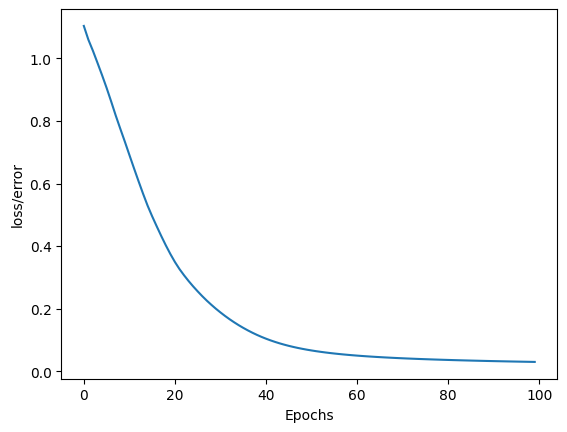

In [163]:
plt.plot(range(epochs),losses)
plt.ylabel("loss/error")
plt.xlabel("Epochs")